In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [2]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [3]:
freq_table = df["category"].value_counts()

In [4]:
freq_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [5]:
df["category"].describe()

count               2443651
unique                  296
top       Sports & Outdoors
freq                 836265
Name: category, dtype: object

In [6]:
# Top 5 most listed product categories: Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body and Birthday Gifts        


In [7]:
top5 = df["category"].value_counts().sort_values(ascending=False).head(5)

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


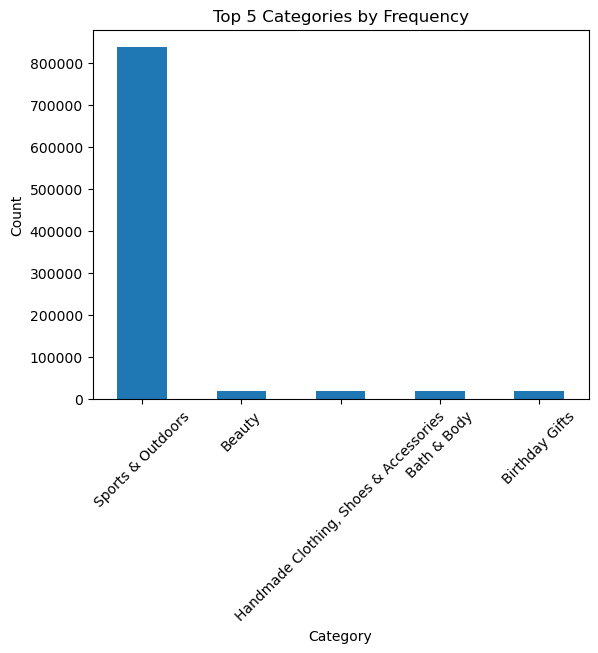

In [9]:
import matplotlib.pyplot as plt

top5.plot(kind="bar")

plt.title("Top 5 Categories by Frequency")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

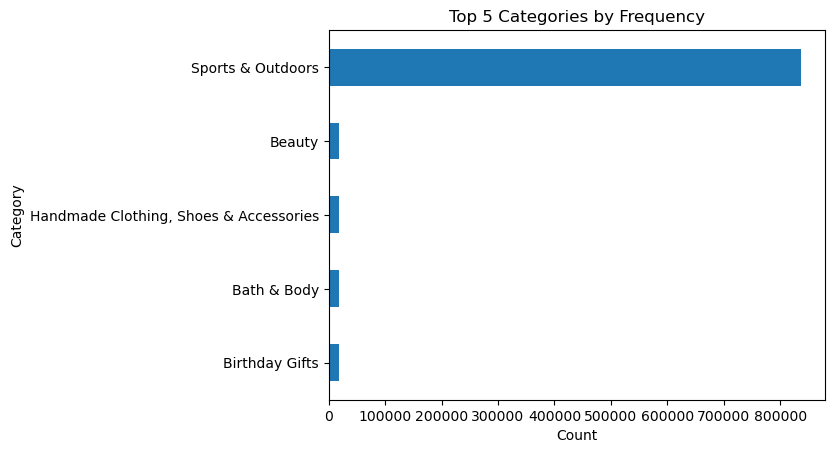

In [10]:
top5 = df["category"].value_counts().sort_values(ascending=False).head(5)

top5.plot(kind="barh")

plt.title("Top 5 Categories by Frequency")
plt.xlabel("Count")
plt.ylabel("Category")

plt.gca().invert_yaxis()   # maior valor no topo
plt.show()

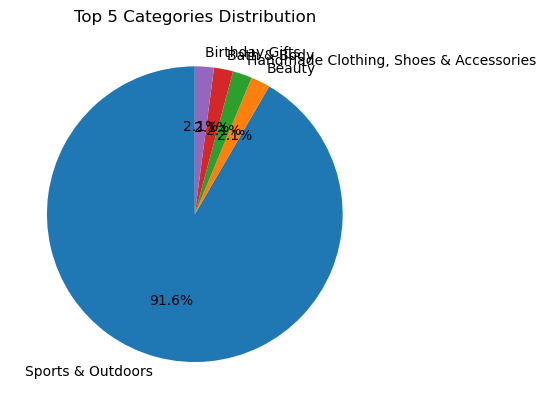

In [11]:

top5.plot(
    kind="pie",
    autopct="%1.1f%%",   # mostra percentagens
    startangle=90
)

plt.title("Top 5 Categories Distribution")
plt.ylabel("")   # remove label automático
plt.show()

In [12]:
# Part 2: Delving into Product Pricing

In [13]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [14]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

In [15]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print("Mean:", mean_price)
print("Median:", median_price)
print("Mode:", mode_price)

Mean: 89.24380943923661
Median: 19.09
Mode: 9.99


In [16]:
price = df["price"]

variance = price.var()
std_dev = price.std()
price_range = price.max() - price.min()
iqr = price.quantile(0.75) - price.quantile(0.25)

print("Variance:", variance)
print("Standard Deviation:", std_dev)
print("Range:", price_range)
print("Interquartile Range (IQR):", iqr)

Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range (IQR): 36.0


C:\Users\Utilizador\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


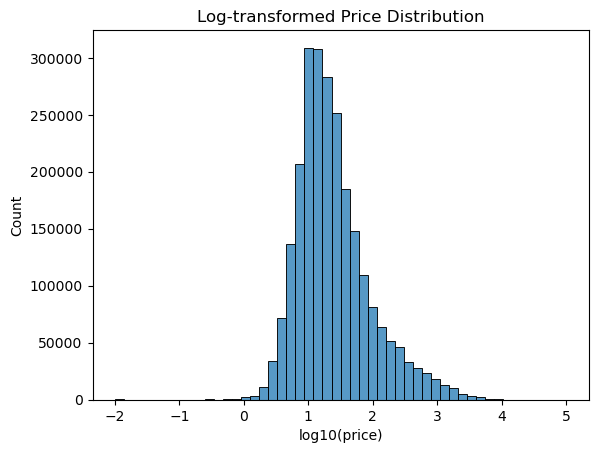

In [17]:
sns.histplot(np.log10(df["price"]), bins=50)

plt.xlabel("log10(price)")
plt.title("Log-transformed Price Distribution")

plt.show()

In [21]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [23]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print("Mean:", mean_rating)
print("Median:", median_rating)
print("Mode:", mode_rating)

Mean: 2.152836472966066
Median: 0.0
Mode: 0.0


In [24]:
df["stars"].value_counts()

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [28]:
df["stars"].nunique()


42

In [31]:
# customers generally rate produts with 0 stars.

In [36]:
rating_variance = df["stars"].var()
standard_deviation = df["stars"].std()
iqr = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print("Variance:", rating_variance)
print("Standard_deviation:", standard_deviation)
print("iqr:", iqr)

Variance: 4.81743402976196
Standard_deviation: 2.1948653785054697
iqr: 4.4


In [37]:
# there is a wide variation in customer feedback

In [39]:
skewness = df['stars'].skew()
print("Skewness:", skewness)

kurtosis = df['stars'].kurt()
print("Kurtosis:", kurtosis)

Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994


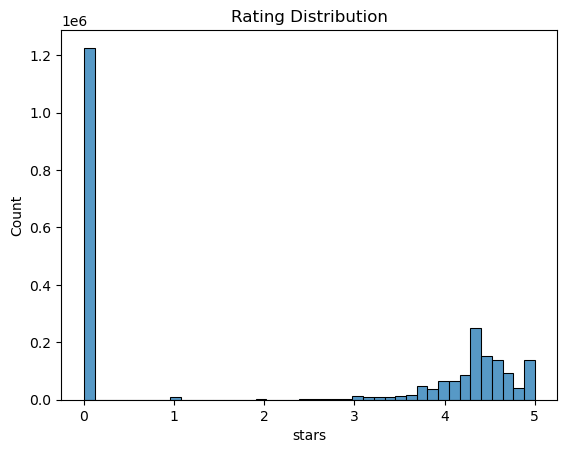

In [30]:
sns.histplot((df["stars"]), bins=42)

plt.xlabel("stars")
plt.title("Rating Distribution")

plt.show()

In [ ]:
# 0 is more common 